# support vector machine

In [1]:
# import libarires
%pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached pandas-3.0.5-cp312-cp312-win_amd64.whl.metadata (19 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached pandas-3.0.5-cp312-cp312-win_amd64.whl (9.8 MB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)

   ---------------------------------------- 0/6 [joblib]
   ---------------------------------------- 0/6 [joblib]
   ---------------------------------------- 0/6 [joblib]
   ---------------------------------

In [2]:
# import libarires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# load the dataset
df=pd.read_csv("C:\\Users\\guntu\\OneDrive\\Desktop\\SVM\\svm\\SVM_Dataset.csv")
df

,buying,maint,doors,persons,lug_boot,safety,car
0,vhigh,vhigh,two,two,small,low,unacc
1,vhigh,vhigh,two,two,small,med,unacc
2,vhigh,vhigh,two,two,small,high,unacc
3,vhigh,vhigh,two,two,med,low,unacc
4,vhigh,vhigh,two,two,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


In [6]:
# data preproccessing
df.isnull().sum()

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
car         0
dtype: int64

In [7]:
df.duplicated().any()

np.False_

In [8]:
df.head()

,buying,maint,doors,persons,lug_boot,safety,car
0,vhigh,vhigh,two,two,small,low,unacc
1,vhigh,vhigh,two,two,small,med,unacc
2,vhigh,vhigh,two,two,small,high,unacc
3,vhigh,vhigh,two,two,med,low,unacc
4,vhigh,vhigh,two,two,med,med,unacc


In [9]:
df.shape

(1728, 7)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   buying    1728 non-null   str  
 1   maint     1728 non-null   str  
 2   doors     1728 non-null   str  
 3   persons   1728 non-null   str  
 4   lug_boot  1728 non-null   str  
 5   safety    1728 non-null   str  
 6   car       1728 non-null   str  
dtypes: str(7)
memory usage: 94.6 KB


In [11]:
df.describe()

,buying,maint,doors,persons,lug_boot,safety,car
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,two,two,small,low,unacc
freq,432,432,432,576,576,576,1210


In [13]:
df['doors'].value_counts()

doors
two      432
three    432
four     432
5more    432
Name: count, dtype: int64

In [27]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    log_loss
)

import joblib

In [28]:
print("\nCar Class Distribution:")
print(df["car"].value_counts())


Car Class Distribution:
car
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


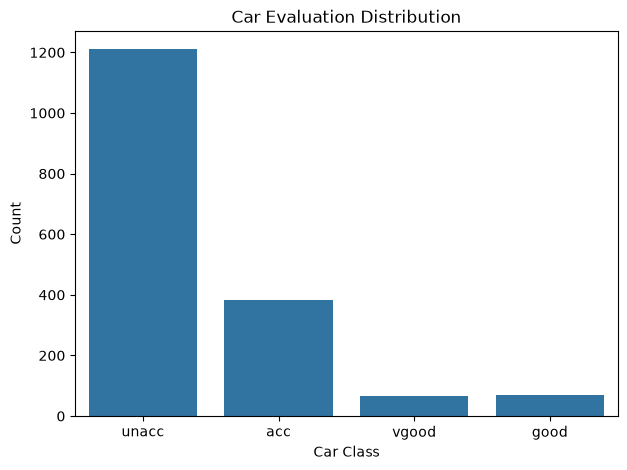

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x="car",
    data=df
)

plt.title("Car Evaluation Distribution")
plt.xlabel("Car Class")
plt.ylabel("Count")

plt.show()

In [30]:
X = df[
    [
        "buying",
        "maint",
        "doors",
        "persons",
        "lug_boot",
        "safety"
    ]
]

y = df["car"]

In [ ]:
# Import the train and test model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [32]:
categorical_columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety"
]

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        )
    ]
)

In [34]:
X_train_encoded = preprocessor.fit_transform(
    X_train
)

In [35]:
X_test_encoded = preprocessor.transform(
    X_test
)

In [ ]:
# Import the StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Scaling completed")

Scaling completed


In [43]:
X_train_scaled = scaler.fit_transform(
    X_train_encoded
)

In [44]:
X_test_scaled = scaler.transform(
    X_test_encoded
)

In [45]:
rbf_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

In [ ]:
# Import the Model
from sklearn.svm import SVC

rbf_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

# TRAIN THE MODEL
rbf_model.fit(X_train_scaled, y_train)

print("RBF SVM model trained successfully!")

c:\Users\guntu\OneDrive\Desktop\SVM\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RBF SVM model trained successfully!


In [49]:

y_pred_rbf = rbf_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred_rbf)

Predictions:
['good' 'unacc' 'unacc' 'unacc' 'acc' 'unacc' 'unacc' 'acc' 'unacc'
 'unacc' 'unacc' 'unacc' 'unacc' 'unacc' 'vgood' 'unacc' 'acc' 'unacc'
 'unacc' 'unacc' 'unacc' 'unacc' 'unacc' 'unacc' 'unacc' 'unacc' 'unacc'
 'unacc' 'unacc' 'good' 'unacc' 'unacc' 'acc' 'unacc' 'unacc' 'vgood'
 'unacc' 'unacc' 'acc' 'unacc' 'acc' 'acc' 'acc' 'unacc' 'unacc' 'acc'
 'unacc' 'unacc' 'unacc' 'acc' 'unacc' 'acc' 'unacc' 'unacc' 'unacc' 'acc'
 'vgood' 'unacc' 'good' 'unacc' 'acc' 'acc' 'unacc' 'acc' 'acc' 'unacc'
 'unacc' 'acc' 'unacc' 'acc' 'unacc' 'unacc' 'acc' 'unacc' 'unacc' 'good'
 'acc' 'unacc' 'acc' 'acc' 'unacc' 'unacc' 'unacc' 'unacc' 'unacc' 'unacc'
 'unacc' 'unacc' 'unacc' 'acc' 'unacc' 'unacc' 'unacc' 'unacc' 'acc' 'acc'
 'unacc' 'unacc' 'good' 'unacc' 'unacc' 'unacc' 'acc' 'unacc' 'unacc'
 'unacc' 'acc' 'good' 'unacc' 'acc' 'vgood' 'vgood' 'unacc' 'unacc' 'acc'
 'good' 'unacc' 'unacc' 'acc' 'unacc' 'unacc' 'unacc' 'unacc' 'acc' 'acc'
 'vgood' 'unacc' 'unacc' 'acc' 'vgood' 'acc' 

In [ ]:
# Accuracy
from sklearn.metrics import accuracy_score

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("RBF SVM Accuracy:", accuracy_rbf)

RBF SVM Accuracy: 0.9624277456647399
